# Credit Scoring Model

## 1. Project Overview

The Credit Scoring Model is a Machine Learning project that predicts an individual's creditworthiness based on their financial history and personal information.

The main objective of this project is to classify applicants into two categories:
- **Good Credit:** Applicants with a good credit history.
- **Bad Credit:** Applicants who may have a higher credit risk.

## 2. Dataset Information

- **Dataset:** German Credit Dataset
- **Source:** UCI Machine Learning Repository
- **Total Records:** 1,000
- **Original Features:** 20
- **Target Classes:** Good Credit and Bad Credit

## 3. Technologies and Libraries Used

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Joblib

## 4. Machine Learning Algorithms

The following classification algorithms were implemented and compared:
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Tuned Logistic Regression

## 5. Project Workflow

1. Dataset collection and loading
2. Data exploration and cleaning
3. Data preprocessing
4. Feature engineering
5. Splitting data into training and testing sets
6. Model training and evaluation
7. Hyperparameter tuning
8. Model comparison and selection
9. Saving the final trained model

In [4]:
!pip install ucimlrepo

In [5]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
# Fetch German Credit dataset

credit_data = fetch_ucirepo(id=144)

# Separate features and target
X = credit_data.data.features
y = credit_data.data.targets

# Display dataset
print("Dataset loaded successfully!")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Features shape: (1000, 20)
Target shape: (1000, 1)


In [7]:
# Display first five rows

print("First five records:")
display(X.head())

First five records:


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [8]:
print("Number of rows:", X.shape[0])
print("Number of columns:", X.shape[1])

Number of rows: 1000
Number of columns: 20


In [9]:
print("Dataset information:")
X.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Attribute1   1000 non-null   object
 1   Attribute2   1000 non-null   int64 
 2   Attribute3   1000 non-null   object
 3   Attribute4   1000 non-null   object
 4   Attribute5   1000 non-null   int64 
 5   Attribute6   1000 non-null   object
 6   Attribute7   1000 non-null   object
 7   Attribute8   1000 non-null   int64 
 8   Attribute9   1000 non-null   object
 9   Attribute10  1000 non-null   object
 10  Attribute11  1000 non-null   int64 
 11  Attribute12  1000 non-null   object
 12  Attribute13  1000 non-null   int64 
 13  Attribute14  1000 non-null   object
 14  Attribute15  1000 non-null   object
 15  Attribute16  1000 non-null   int64 
 16  Attribute17  1000 non-null   object
 17  Attribute18  1000 non-null   int64 
 18  Attribute19  1000 non-null   object
 19  Attribu

In [10]:
print("Target values:")
print(y.head())

print("\nUnique target values:")
print(y.iloc[:, 0].unique())

Target values:
   class
0      1
1      2
2      1
3      1
4      2

Unique target values:
[1 2]


In [11]:
print("Missing values:")
print(X.isnull().sum())

Missing values:
Attribute1     0
Attribute2     0
Attribute3     0
Attribute4     0
Attribute5     0
Attribute6     0
Attribute7     0
Attribute8     0
Attribute9     0
Attribute10    0
Attribute11    0
Attribute12    0
Attribute13    0
Attribute14    0
Attribute15    0
Attribute16    0
Attribute17    0
Attribute18    0
Attribute19    0
Attribute20    0
dtype: int64


In [12]:
print("Duplicate records:", X.duplicated().sum())

Duplicate records: 0


In [13]:
# Count good and bad credit applicants

print("Credit Class Distribution:")
print(y.iloc[:, 0].value_counts().sort_index())

# Calculate percentages
print("\nCredit Class Percentage:")
print(y.iloc[:, 0].value_counts(normalize=True) * 100)

Credit Class Distribution:
class
1    700
2    300
Name: count, dtype: int64

Credit Class Percentage:
class
1    70.0
2    30.0
Name: proportion, dtype: float64


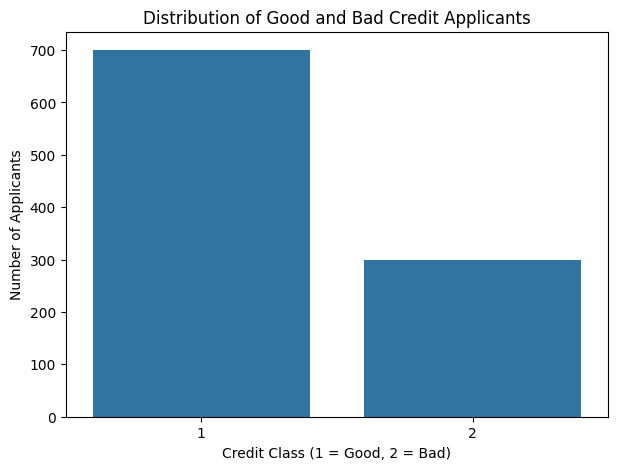

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(x=y.iloc[:, 0])

plt.title("Distribution of Good and Bad Credit Applicants")
plt.xlabel("Credit Class (1 = Good, 2 = Bad)")
plt.ylabel("Number of Applicants")

plt.show()

In [15]:
print("Numerical Feature Statistics:")
display(X.describe().T)

Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
Attribute2,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
Attribute5,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Attribute8,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
Attribute11,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
Attribute13,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
Attribute16,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
Attribute18,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


In [16]:
categorical_columns = X.select_dtypes(include='object').columns

for col in categorical_columns:
    print("\nFeature:", col)
    print(X[col].value_counts().head())


Feature: Attribute1
Attribute1
A14    394
A11    274
A12    269
A13     63
Name: count, dtype: int64

Feature: Attribute3
Attribute3
A32    530
A34    293
A33     88
A31     49
A30     40
Name: count, dtype: int64

Feature: Attribute4
Attribute4
A43    280
A40    234
A42    181
A41    103
A49     97
Name: count, dtype: int64

Feature: Attribute6
Attribute6
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64

Feature: Attribute7
Attribute7
A73    339
A75    253
A74    174
A72    172
A71     62
Name: count, dtype: int64

Feature: Attribute9
Attribute9
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

Feature: Attribute10
Attribute10
A101    907
A103     52
A102     41
Name: count, dtype: int64

Feature: Attribute12
Attribute12
A123    332
A121    282
A122    232
A124    154
Name: count, dtype: int64

Feature: Attribute14
Attribute14
A143    814
A141    139
A142     47
Name: count, dtype: int64

Feature: Attribute15
Attribute15
A152    71

In [17]:
print("Missing target values:", y.isnull().sum().sum())

combined_data = pd.concat([X, y], axis=1)

print("Complete duplicate records:", combined_data.duplicated().sum())

Missing target values: 0
Complete duplicate records: 0


In [18]:
print("Credit Class Distribution:")
print(y.iloc[:, 0].value_counts().sort_index())

print("\nCredit Class Percentage:")
print(y.iloc[:, 0].value_counts(normalize=True) * 100)

Credit Class Distribution:
class
1    700
2    300
Name: count, dtype: int64

Credit Class Percentage:
class
1    70.0
2    30.0
Name: proportion, dtype: float64


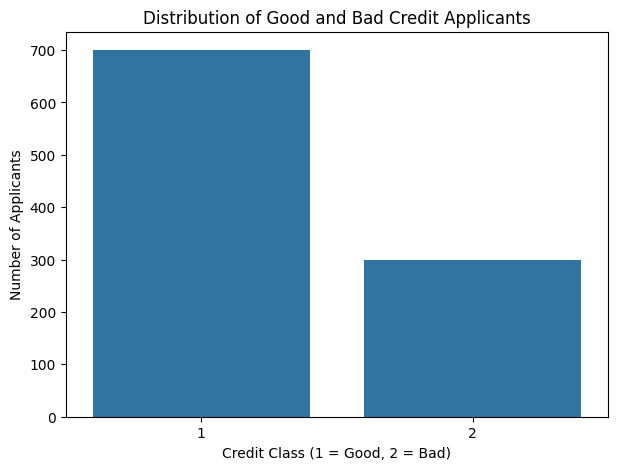

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(x=y.iloc[:, 0])

plt.title("Distribution of Good and Bad Credit Applicants")
plt.xlabel("Credit Class (1 = Good, 2 = Bad)")
plt.ylabel("Number of Applicants")

plt.show()

In [20]:
print("Numerical Feature Statistics:")
display(X.describe().T)

Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
Attribute2,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
Attribute5,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Attribute8,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
Attribute11,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
Attribute13,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
Attribute16,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
Attribute18,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


In [21]:
categorical_columns = X.select_dtypes(include='object').columns

for col in categorical_columns:
    print("\nFeature:", col)
    print(X[col].value_counts().head())


Feature: Attribute1
Attribute1
A14    394
A11    274
A12    269
A13     63
Name: count, dtype: int64

Feature: Attribute3
Attribute3
A32    530
A34    293
A33     88
A31     49
A30     40
Name: count, dtype: int64

Feature: Attribute4
Attribute4
A43    280
A40    234
A42    181
A41    103
A49     97
Name: count, dtype: int64

Feature: Attribute6
Attribute6
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64

Feature: Attribute7
Attribute7
A73    339
A75    253
A74    174
A72    172
A71     62
Name: count, dtype: int64

Feature: Attribute9
Attribute9
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64

Feature: Attribute10
Attribute10
A101    907
A103     52
A102     41
Name: count, dtype: int64

Feature: Attribute12
Attribute12
A123    332
A121    282
A122    232
A124    154
Name: count, dtype: int64

Feature: Attribute14
Attribute14
A143    814
A141    139
A142     47
Name: count, dtype: int64

Feature: Attribute15
Attribute15
A152    71

In [22]:
print("Missing target values:", y.isnull().sum().sum())

combined_data = pd.concat([X, y], axis=1)

print("Complete duplicate records:", combined_data.duplicated().sum())

Missing target values: 0
Complete duplicate records: 0


In [23]:
column_names = {
    'Attribute1': 'checking_account',
    'Attribute2': 'duration',
    'Attribute3': 'credit_history',
    'Attribute4': 'purpose',
    'Attribute5': 'credit_amount',
    'Attribute6': 'savings_account',
    'Attribute7': 'employment',
    'Attribute8': 'installment_rate',
    'Attribute9': 'personal_status',
    'Attribute10': 'other_debtors',
    'Attribute11': 'residence_since',
    'Attribute12': 'property',
    'Attribute13': 'age',
    'Attribute14': 'other_installment_plans',
    'Attribute15': 'housing',
    'Attribute16': 'existing_credits',
    'Attribute17': 'job',
    'Attribute18': 'num_dependents',
    'Attribute19': 'telephone',
    'Attribute20': 'foreign_worker'
}

X = X.rename(columns=column_names)

print("Updated column names:")
print(X.columns.tolist())

display(X.head())

Updated column names:
['checking_account', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_account', 'employment', 'installment_rate', 'personal_status', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'telephone', 'foreign_worker']


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [24]:
y = y.iloc[:, 0].map({1: 0, 2: 1})

print("Updated Target Distribution:")
print(y.value_counts())

print("\nTarget Meaning:")
print("0 = Good Credit")
print("1 = Bad Credit")

Updated Target Distribution:
class
0    700
1    300
Name: count, dtype: int64

Target Meaning:
0 = Good Credit
1 = Bad Credit


In [25]:
numerical_columns = X.select_dtypes(include=['int64', 'float64']).columns

categorical_columns = X.select_dtypes(include=['object']).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Categorical Columns:
['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment', 'personal_status', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (800, 20)
Testing data shape: (200, 20)

Training target distribution:
class
0    560
1    240
Name: count, dtype: int64

Testing target distribution:
class
0    140
1     60
Name: count, dtype: int64


In [28]:
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [29]:
from sklearn.linear_model import LogisticRegression

In [30]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

In [31]:
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [32]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_lr[:10])

First 10 Actual Values:
[0 0 1 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 1 0 0 0 0 0 0 0]


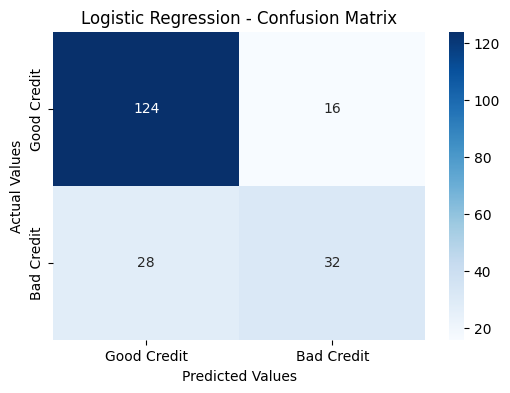

In [33]:
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Good Credit', 'Bad Credit'],
    yticklabels=['Good Credit', 'Bad Credit']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [34]:
results = []

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1 Score': f1_score(y_test, y_pred_lr),
    'ROC-AUC': roc_auc_score(y_test, y_prob_lr)
})

print("Logistic Regression results saved!")

Logistic Regression results saved!


In [35]:
from sklearn.tree import DecisionTreeClassifier

In [36]:
decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

In [37]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [38]:
y_pred_dt = decision_tree_model.predict(X_test)

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("First 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_dt[:10])

First 10 Actual Values:
[0 0 1 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 1 0 0 0 1 0 0]


In [39]:
print("Decision Tree Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Performance
Accuracy: 0.63
Precision: 0.3793103448275862
Recall: 0.36666666666666664
F1 Score: 0.3728813559322034
ROC-AUC: 0.5547619047619048

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.74      0.74       140
           1       0.38      0.37      0.37        60

    accuracy                           0.63       200
   macro avg       0.56      0.55      0.56       200
weighted avg       0.63      0.63      0.63       200



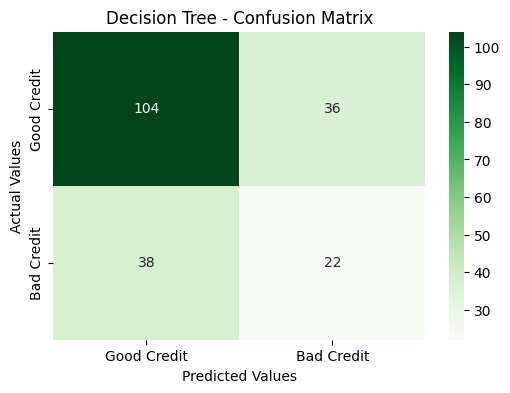

In [40]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Good Credit', 'Bad Credit'],
    yticklabels=['Good Credit', 'Bad Credit']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Decision Tree - Confusion Matrix")

plt.show()

In [41]:
results.append({
    'Model': 'Decision Tree',
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall': recall_score(y_test, y_pred_dt),
    'F1 Score': f1_score(y_test, y_pred_dt),
    'ROC-AUC': roc_auc_score(y_test, y_prob_dt)
})

print("Decision Tree results saved!")

Decision Tree results saved!


In [42]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [43]:
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [44]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [45]:
print("Random Forest Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance
Accuracy: 0.74
Precision: 0.6052631578947368
Recall: 0.38333333333333336
F1 Score: 0.46938775510204084
ROC-AUC: 0.7792857142857142

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.89      0.83       140
           1       0.61      0.38      0.47        60

    accuracy                           0.74       200
   macro avg       0.69      0.64      0.65       200
weighted avg       0.72      0.74      0.72       200



In [46]:
results.append({
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1 Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
})

print("Random Forest results saved!")

Random Forest results saved!


In [47]:
import pandas as pd

results_df = pd.DataFrame(results)

# Remove duplicate entries if a results cell was executed more than once
results_df = results_df.drop_duplicates(
    subset='Model',
    keep='last'
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.78,0.6667,0.5333,0.5926,0.8040
1,Decision Tree,0.63,0.3793,0.3667,0.3729,0.5548
2,Random Forest,0.74,0.6053,0.3833,0.4694,0.7793


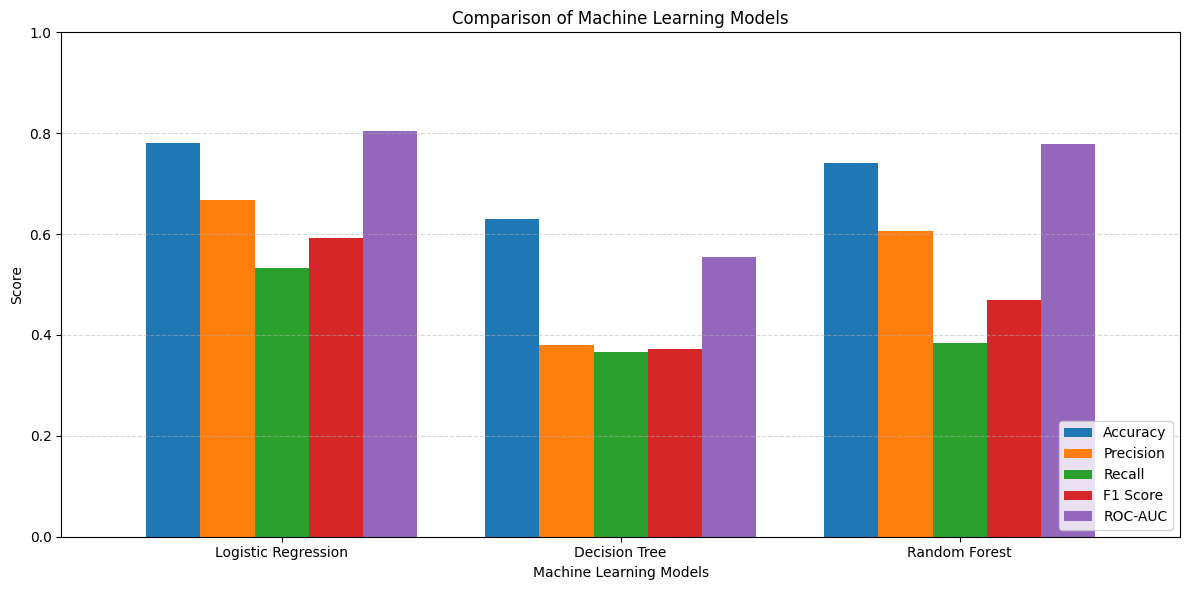

In [48]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [49]:
results_df.to_csv('credit_scoring_model_comparison.csv', index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [50]:
from sklearn.model_selection import GridSearchCV

In [51]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}

In [52]:
grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    n_jobs=-1
)

In [53]:
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Recall:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best Cross-Validation Recall:
0.7166666666666667


In [54]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

print("Tuned Logistic Regression Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned Logistic Regression Performance
Accuracy: 0.725
Precision: 0.5280898876404494
Recall: 0.7833333333333333
F1 Score: 0.6308724832214765
ROC-AUC: 0.809404761904762

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.70      0.78       140
           1       0.53      0.78      0.63        60

    accuracy                           0.72       200
   macro avg       0.71      0.74      0.71       200
weighted avg       0.78      0.72      0.74       200



In [55]:
{
    'classifier__C': 0.1,
    'classifier__class_weight': 'balanced'
}

{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

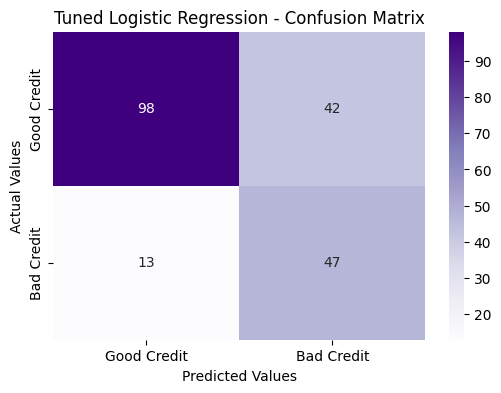

In [56]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Good Credit', 'Bad Credit'],
    yticklabels=['Good Credit', 'Bad Credit']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Tuned Logistic Regression - Confusion Matrix")

plt.show()

In [57]:
results.append({
    'Model': 'Tuned Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned),
    'Recall': recall_score(y_test, y_pred_tuned),
    'F1 Score': f1_score(y_test, y_pred_tuned),
    'ROC-AUC': roc_auc_score(y_test, y_prob_tuned)
})

results_df = pd.DataFrame(results)

results_df = results_df.drop_duplicates(
    subset='Model',
    keep='last'
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.780,0.6667,0.5333,0.5926,0.8040
1,Decision Tree,0.630,0.3793,0.3667,0.3729,0.5548
2,Random Forest,0.740,0.6053,0.3833,0.4694,0.7793
3,Tuned Logistic Regression,0.725,0.5281,0.7833,0.6309,0.8094


In [58]:
results_df.to_csv(
    'credit_scoring_model_comparison.csv',
    index=False
)

print("Updated comparison saved successfully!")

Updated comparison saved successfully!


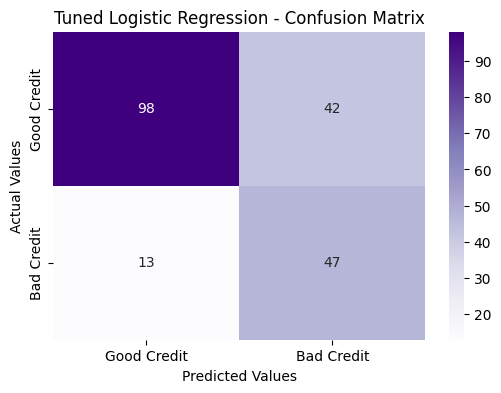

[[98 42]
 [13 47]]


In [59]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['Good Credit', 'Bad Credit'],
    yticklabels=['Good Credit', 'Bad Credit']
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Tuned Logistic Regression - Confusion Matrix')
plt.show()

print(cm_tuned)

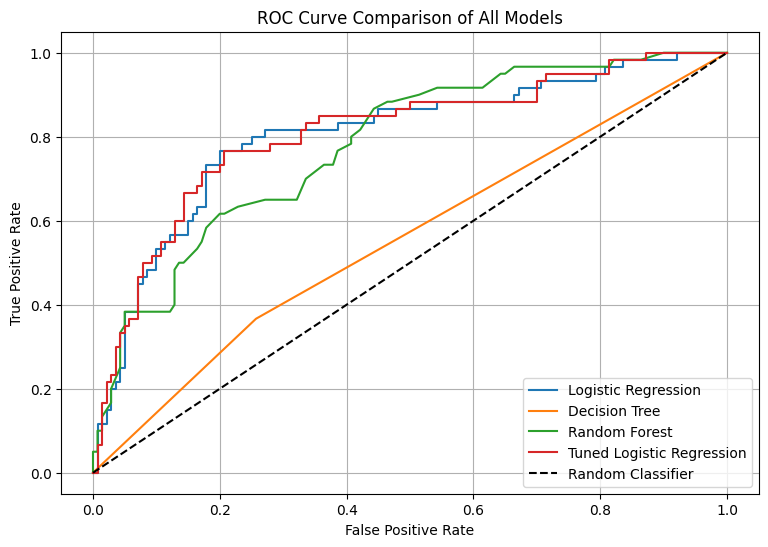

In [60]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calculate ROC curve for each model
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_prob_tuned)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(fpr_lr, tpr_lr, label='Logistic Regression')
plt.plot(fpr_dt, tpr_dt, label='Decision Tree')
plt.plot(fpr_rf, tpr_rf, label='Random Forest')
plt.plot(fpr_tuned, tpr_tuned, label='Tuned Logistic Regression')

# Random classifier reference line
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of All Models')

plt.legend()
plt.grid()
plt.show()

In [61]:
import joblib

# Save the final trained model
joblib.dump(best_model, 'credit_scoring_model.pkl')

print("Final model saved successfully!")

Final model saved successfully!


In [62]:
results_df.to_csv('credit_scoring_model_comparison.csv', index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [63]:
import joblib

# Load the saved model
loaded_model = joblib.load('credit_scoring_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [64]:
# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Compare with the original model predictions
print("First 10 predictions:", loaded_predictions[:10])

print("\nOriginal predictions:", y_pred_tuned[:10])

# Check whether both predictions match
if (loaded_predictions == y_pred_tuned).all():
    print("\nVerification successful! Both predictions match.")
else:
    print("\nThere is a difference in predictions.")

First 10 predictions: [1 0 1 1 0 0 0 0 1 0]

Original predictions: [1 0 1 1 0 0 0 0 1 0]

Verification successful! Both predictions match.


In [65]:
new_applicant = pd.DataFrame([{
    'checking_account': 'A11',
    'duration': 12,
    'credit_history': 'A34',
    'purpose': 'A43',
    'credit_amount': 3000,
    'savings_account': 'A65',
    'employment': 'A73',
    'installment_rate': 2,
    'personal_status': 'A93',
    'other_debtors': 'A101',
    'residence_since': 3,
    'property': 'A121',
    'age': 30,
    'other_installment_plans': 'A143',
    'housing': 'A152',
    'existing_credits': 1,
    'job': 'A173',
    'num_dependents': 1,
    'telephone': 'A191',
    'foreign_worker': 'A201'
}])

display(new_applicant)

,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,residence_since,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker
0,A11,12,A34,A43,3000,A65,A73,2,A93,A101,3,A121,30,A143,A152,1,A173,1,A191,A201


In [66]:
prediction = loaded_model.predict(new_applicant)

if prediction[0] == 0:
    print("Prediction: Good Credit")
else:
    print("Prediction: Bad Credit")

Prediction: Good Credit


In [67]:
# Create a new feature in training and testing datasets

X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

X_train_fe['credit_amount_per_month'] = (
    X_train_fe['credit_amount'] / X_train_fe['duration']
)

X_test_fe['credit_amount_per_month'] = (
    X_test_fe['credit_amount'] / X_test_fe['duration']
)

print("Training data shape:", X_train_fe.shape)
print("Testing data shape:", X_test_fe.shape)

display(X_train_fe.head())

Training data shape: (800, 21)
Testing data shape: (200, 21)


,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_amount_per_month
828,A11,36,A32,A41,8335,A65,A75,3,A93,A101,...,A124,47,A143,A153,1,A173,1,A191,A201,231.527778
997,A14,12,A32,A43,804,A61,A75,4,A93,A101,...,A123,38,A143,A152,1,A173,1,A191,A201,67.000000
148,A11,36,A34,A42,5371,A61,A73,3,A93,A103,...,A122,28,A143,A152,2,A173,1,A191,A201,149.194444
735,A12,36,A31,A44,3990,A65,A72,3,A92,A101,...,A124,29,A141,A152,1,A171,1,A191,A201,110.833333
130,A12,48,A32,A40,8487,A65,A74,1,A92,A101,...,A123,24,A143,A152,1,A173,1,A191,A201,176.812500


In [68]:
numerical_columns_fe = X_train_fe.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns_fe = X_train_fe.select_dtypes(
    include=['object']
).columns

print("Numerical columns:", len(numerical_columns_fe))
print("Categorical columns:", len(categorical_columns_fe))

Numerical columns: 8
Categorical columns: 13


In [69]:
numerical_transformer_fe = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer_fe = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_fe = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer_fe, numerical_columns_fe),
        ('cat', categorical_transformer_fe, categorical_columns_fe)
    ]
)

In [70]:
logistic_model_fe = Pipeline(steps=[
    ('preprocessor', preprocessor_fe),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

grid_search_fe = GridSearchCV(
    estimator=logistic_model_fe,
    param_grid=param_grid,
    scoring='recall',
    cv=5,
    n_jobs=-1
)

grid_search_fe.fit(X_train_fe, y_train)

best_model_fe = grid_search_fe.best_estimator_

y_pred_fe = best_model_fe.predict(X_test_fe)
y_prob_fe = best_model_fe.predict_proba(X_test_fe)[:, 1]

print("Best parameters:", grid_search_fe.best_params_)

Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}


In [71]:
print("Feature Engineered Model Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_fe))
print("Precision:", precision_score(y_test, y_pred_fe))
print("Recall:", recall_score(y_test, y_pred_fe))
print("F1 Score:", f1_score(y_test, y_pred_fe))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_fe))

Feature Engineered Model Performance
Accuracy: 0.71
Precision: 0.5113636363636364
Recall: 0.75
F1 Score: 0.6081081081081081
ROC-AUC: 0.7796428571428572


In [72]:
import joblib

# Save the selected final model
joblib.dump(best_model, 'credit_scoring_model.pkl')

print("Final Credit Scoring Model saved successfully!")

Final Credit Scoring Model saved successfully!


In [73]:
loaded_model = joblib.load('credit_scoring_model.pkl')

loaded_predictions = loaded_model.predict(X_test)

print("Model loaded successfully!")
print("Predictions:", loaded_predictions[:10])

Model loaded successfully!
Predictions: [1 0 1 1 0 0 0 0 1 0]


## 6. Final Model Performance

After training and comparing different classification algorithms, Tuned Logistic Regression was selected as the final model.

### Performance Metrics

| Metric | Score |
|---|---:|
| Accuracy | 72.50% |
| Precision | 52.81% |
| Recall | 78.33% |
| F1 Score | 63.09% |
| ROC-AUC | 80.94% |

The tuned model achieved a recall of 78.33%, meaning it correctly identified approximately 78% of the actual bad-credit applicants in the test dataset.

## 7. Conclusion

In this project, a Credit Scoring Model was developed using Machine Learning classification algorithms.

Different models were trained and evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

After comparing the results and performing hyperparameter tuning, Tuned Logistic Regression was selected as the final model.

Feature engineering was also performed by creating an additional feature, but it did not improve the model's performance.

The final model was saved using Joblib for future predictions.

**Note:** This project is developed for educational purposes. Its predictions should not be used as the sole basis for real-world credit or lending decisions.

In [74]:
from google.colab import files

files.download('credit_scoring_model.pkl')
files.download('credit_scoring_model_comparison.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [75]:
import os

print("Current working directory:", os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current working directory: /content

Files available:
['.config', 'credit_scoring_model.pkl', 'credit_scoring_model_comparison.csv', 'sample_data']


In [76]:
import joblib

joblib.dump(best_model, '/content/credit_scoring_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [77]:
results_df.to_csv(
    '/content/credit_scoring_model_comparison.csv',
    index=False
)

print("CSV saved successfully!")

CSV saved successfully!


In [78]:
from google.colab import files

files.download('/content/credit_scoring_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [79]:
files.download('/content/credit_scoring_model_comparison.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>